# Imports

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pylab as plt
import seaborn as sns

# Fonte de dados para analise

- https://medium.com/@renata-biaggi/guia-completo-an%C3%A1lise-explorat%C3%B3ria-de-dados-com-python-2964fa2940f4

# EDA

## Entendendo a base de dados

In [3]:
def transformar_dataset_to_csv(path, path_save, nome):

    colunas = ["id", "date", "Temperature", "Humidity", "Light", "CO2", "HumidityRatio", "Occupancy"]
    colunas_sem_id = ["date", "Temperature", "Humidity", "Light", "CO2", "HumidityRatio", "Occupancy"]
    
    dataset = pd.read_csv(
        path,
        header = 0,
        names = colunas,
        usecols = colunas_sem_id,
        parse_dates = ["date"],
    )

    dataset.to_csv(path_save + f"/{nome}.csv", index=False)
    
    return dataset
    
datatest = transformar_dataset_to_csv("./dataset/occupancy_detection/dataset_txt/datatest.txt", "./dataset/occupancy_detection/dataset_csv", "datatest")
datatest2 = transformar_dataset_to_csv("./dataset/occupancy_detection/dataset_txt/datatest2.txt", "./dataset/occupancy_detection/dataset_csv", "datatest2")
datatraining = transformar_dataset_to_csv("./dataset/occupancy_detection/dataset_txt/datatraining.txt", "./dataset/occupancy_detection/dataset_csv", "datatraining")

In [4]:
dataset_completo = pd.concat([datatest, datatest2, datatraining])

In [5]:
datasets = [datatraining, datatest, datatest2, dataset_completo]

In [6]:
dataset_completo.to_csv("./dataset/occupancy_detection/dataset_csv/dataset_completo.csv")

In [7]:
def resumo_dataset(dataset, nome):
    linha = "=" * 70

    print(linha)
    print(f"Resumo sem graficos do Dataset de Detecção de Ocupação: {nome}")
    print(linha)

    linhas, colunas = dataset.shape
    print(f"\nDimensões: {linhas:,} linhas × {colunas} colunas")

    print(f"\nColunas ({colunas}):")
    for i, (col, dtype) in enumerate(zip(dataset.columns, dataset.dtypes), start=1):
        print(f"{i:>2}.{col:<20} → {dtype}")

    print("A ultima linha é a linha que queremos prever")

    print("\nValores nulos por coluna:")
    nulos = dataset.isnull().sum()
    for col, qtd in nulos.items():
        pct = 100 * qtd / len(dataset)
        marca = "✅" if qtd == 0 else "⚠️"
        print(f"   {marca} {col:<20} {qtd:>6} ({pct:5.2f}%)")

    print("\nPrimeiras 5 linhas:")
    print(dataset.head().to_string())

    print("\nEstatísticas descritivas:")
    print(dataset.describe().round(3).to_string())

    print("\nDados Duplicados:")
    print(dataset.duplicated().sum())

    print("\nDistribuição das Classes:")
    dataset_classes = dataset['Occupancy']

    contagem   = dataset_classes.value_counts().sort_index()
    percentual = dataset_classes.value_counts(normalize=True).sort_index() * 100

    print(f"\n{'Classe':<14}{'Qtd':>12}{'%':>10}")

    for classe in contagem.index:
        print(f"{classe:<14}{contagem[classe]:>12}{percentual[classe]:>9.2f}%")

    print("\n" + linha)
    

In [8]:
resumo_dataset(datatraining, "datatraining")
resumo_dataset(datatest, "datatest")
resumo_dataset(datatest2, "datatest2")
resumo_dataset(dataset_completo, "dataset_completo")

Resumo sem graficos do Dataset de Detecção de Ocupação: datatraining

Dimensões: 8,143 linhas × 7 colunas

Colunas (7):
 1.date                 → datetime64[us]
 2.Temperature          → float64
 3.Humidity             → float64
 4.Light                → float64
 5.CO2                  → float64
 6.HumidityRatio        → float64
 7.Occupancy            → int64
A ultima linha é a linha que queremos prever

Valores nulos por coluna:
   ✅ date                      0 ( 0.00%)
   ✅ Temperature               0 ( 0.00%)
   ✅ Humidity                  0 ( 0.00%)
   ✅ Light                     0 ( 0.00%)
   ✅ CO2                       0 ( 0.00%)
   ✅ HumidityRatio             0 ( 0.00%)
   ✅ Occupancy                 0 ( 0.00%)

Primeiras 5 linhas:
                 date  Temperature  Humidity  Light     CO2  HumidityRatio  Occupancy
0 2015-02-04 17:51:00        23.18   27.2720  426.0  721.25       0.004793          1
1 2015-02-04 17:51:59        23.15   27.2675  429.5  714.00       0.004783    

### Dicionário de variáveis

| Coluna | Descrição | Faixa | Precisão | Resolução | Sensor |
|---|---|---|---|---|---|
| `date` | Timestamp da medição | — | — | 1 min (no dataset) | — |
| `Temperature` | Temperatura do ar (°C) | −40 a 80 °C | ± 0,5 °C | 0,1 °C | DHT22 |
| `Humidity` | Umidade relativa do Ar (%) | 0 a 100 % RH | ± 3 % RH | 0,1 % RH | DHT22 |
| `Light` | Quantidade de Luz no ambiente - Iluminância | 1 a 40 000 lux | N/A | 1 lux | TSL2561 |
| `CO2` | Concentração de CO₂ (ppm) | 0 a 2000 ppm | ± 30 ppm (400–1250 ppm)<br>± 5 % da leitura + 30 ppm (1250–2000 ppm) | 1 ppm | Telaire 6613 |
| `HumidityRatio` | Razão de umidade (kg de vapor / kg de ar seco) — **derivada** de `Temperature` e `Humidity` | — | — | — | — (derivada) |
| `Occupancy` | Variável-alvo binária (1 = ocupado, 0 = vazio) | {0, 1} | — | binária | — (rótulo) |

# Analise das features numericas do dataset em grafico

<Figure size 1500x1500 with 0 Axes>

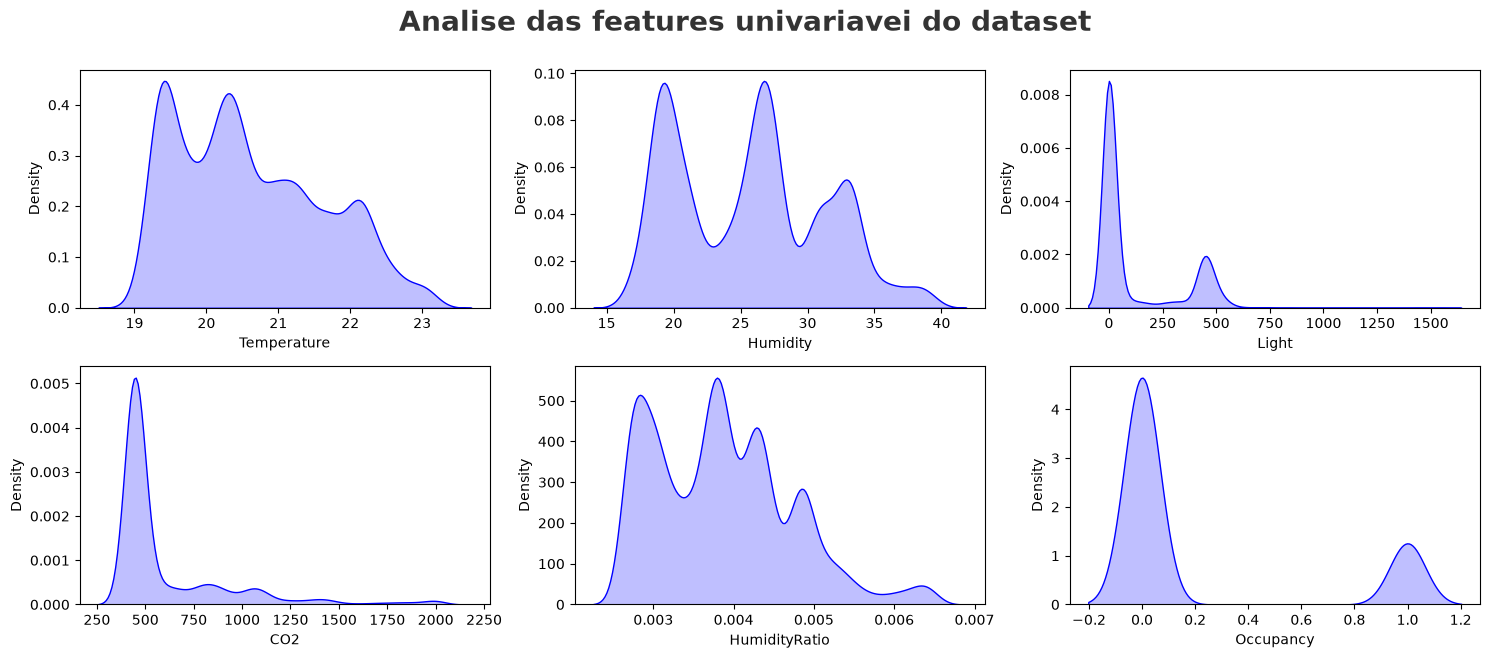

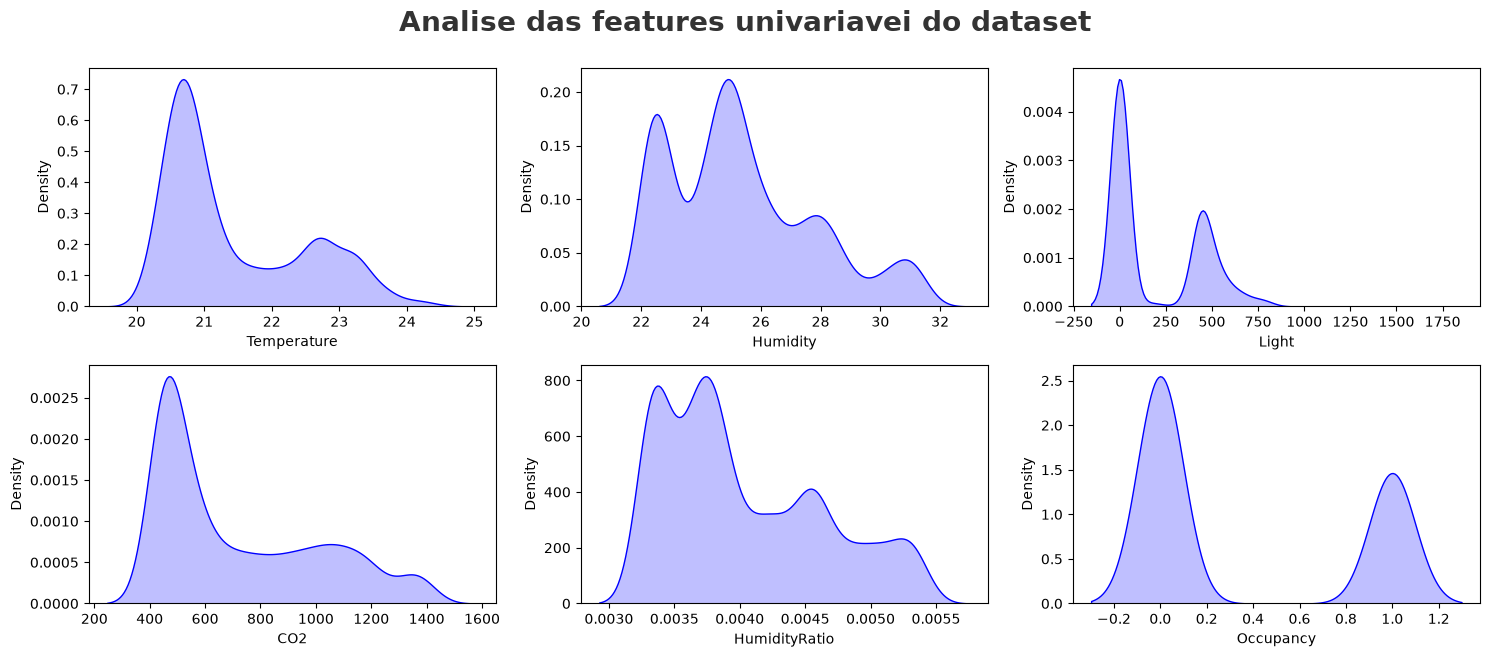

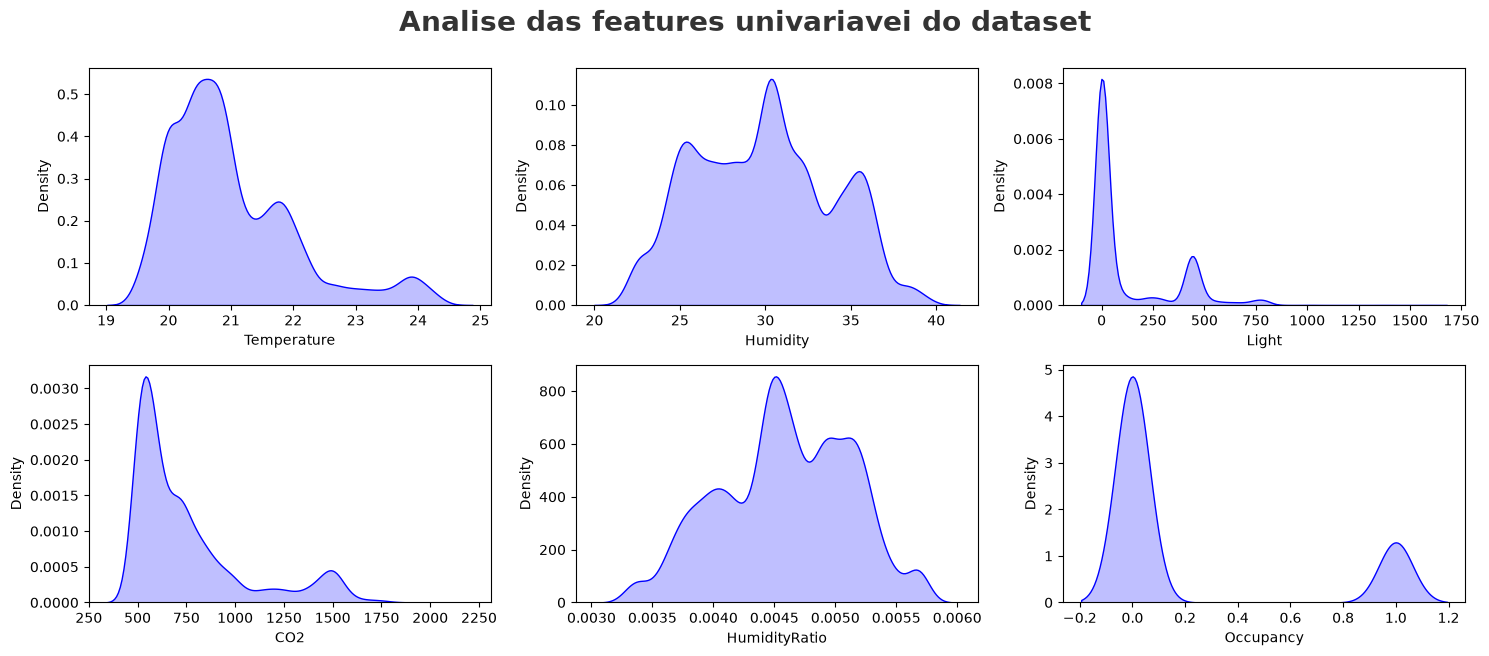

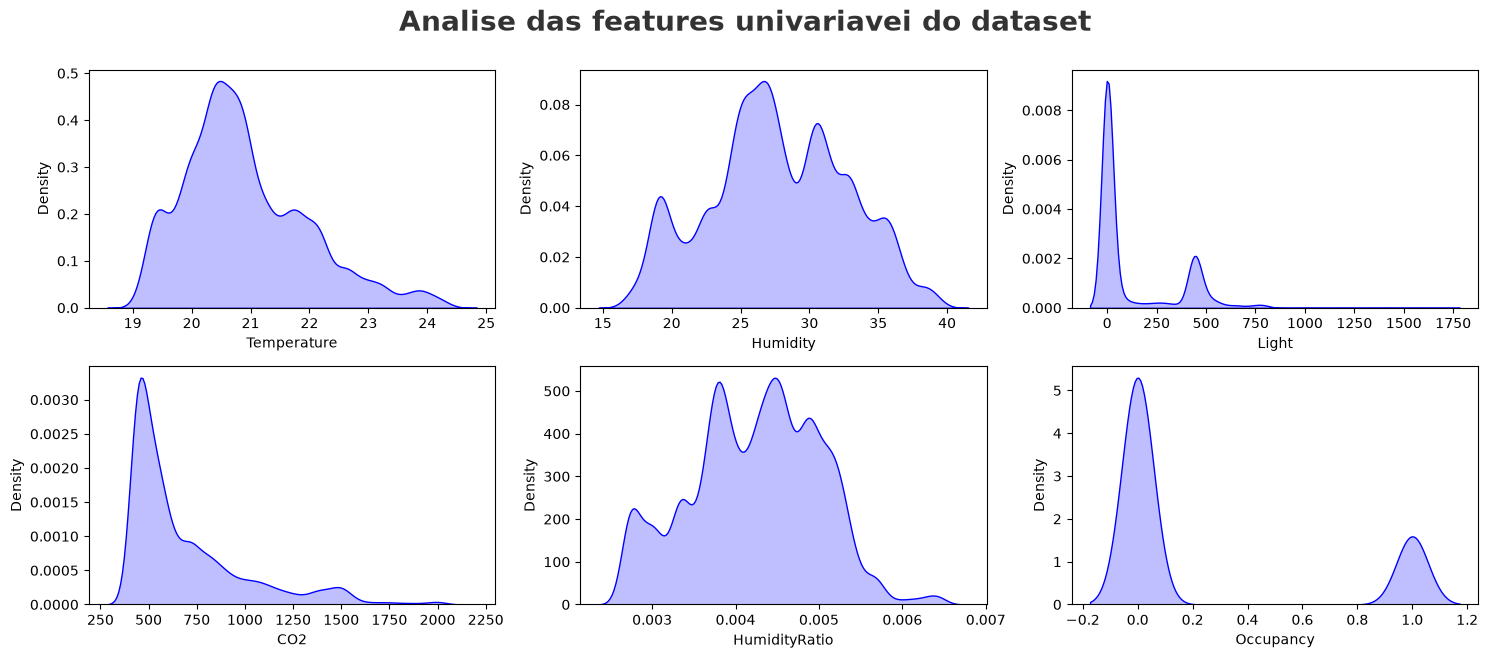

In [9]:
features_numericas = ["Temperature", "Humidity", "Light", "CO2", "HumidityRatio", "Occupancy"]

plt.figure(figsize=(15,15))
plt.suptitle("Analise das features univariavei do dataset", fontsize=20, fontweight='bold', alpha=0.8, y = 1.)

for data in datasets:
    plt.figure(figsize=(15,15))
    plt.suptitle("Analise das features univariavei do dataset", fontsize=20, fontweight='bold', alpha=0.8, y = 1.)
    
    for i in range(len(features_numericas)):
        plt.subplot(5,3, i + 1)
        
        
        sns.kdeplot(x = data[features_numericas[i]], fill=True, color = 'b')
        plt.xlabel(features_numericas[i])
        
    plt.tight_layout() 
    plt.show()

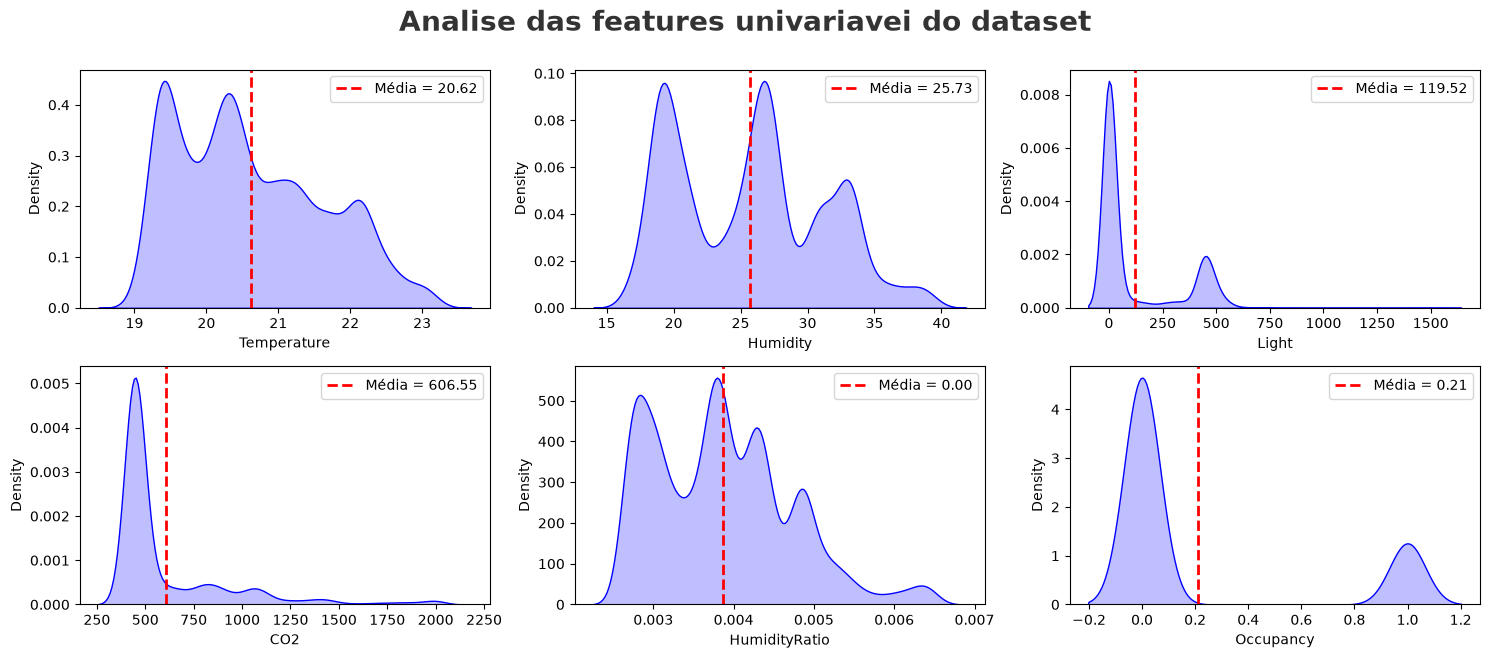

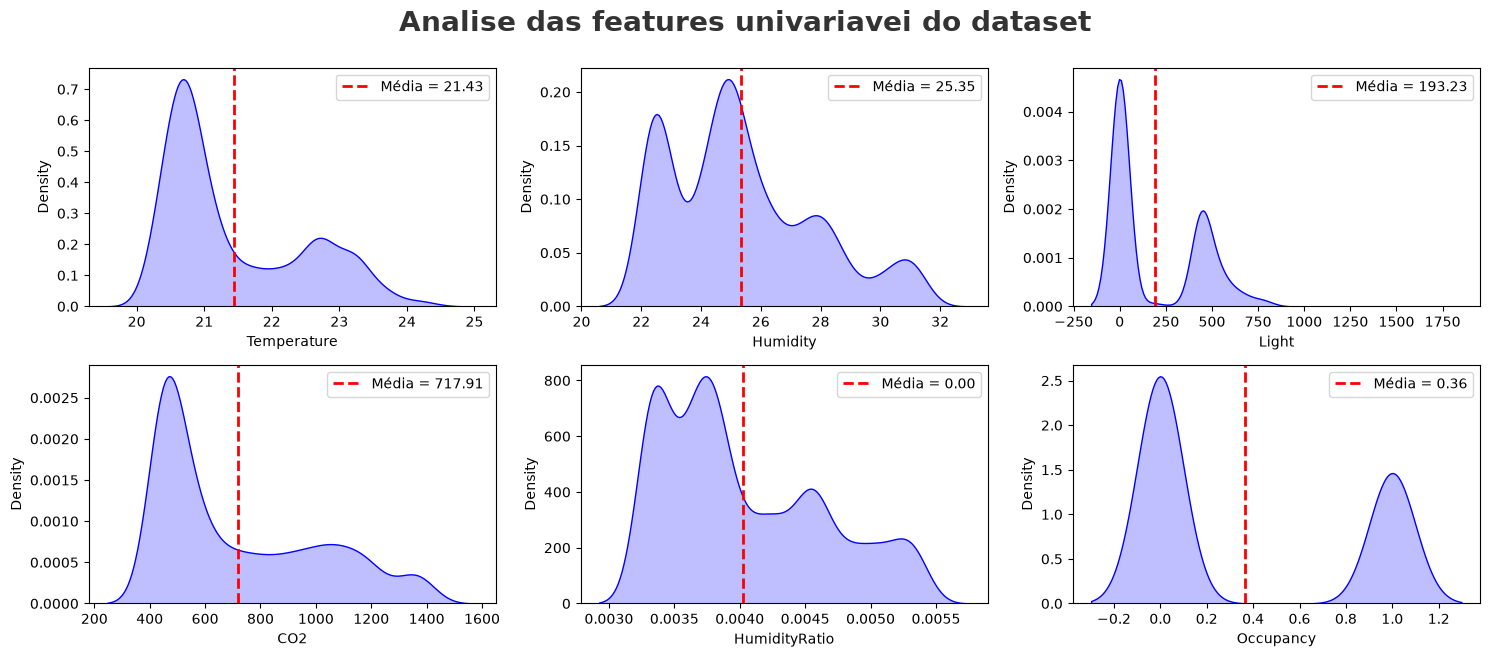

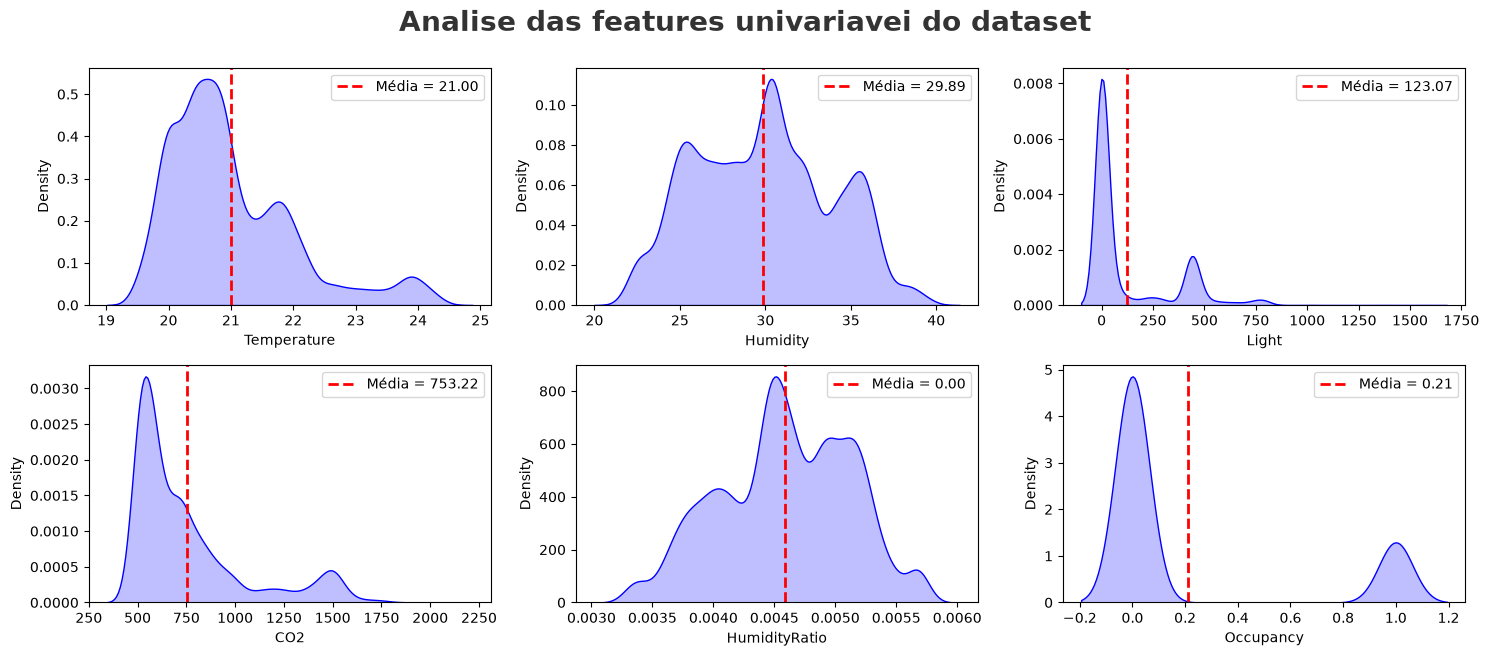

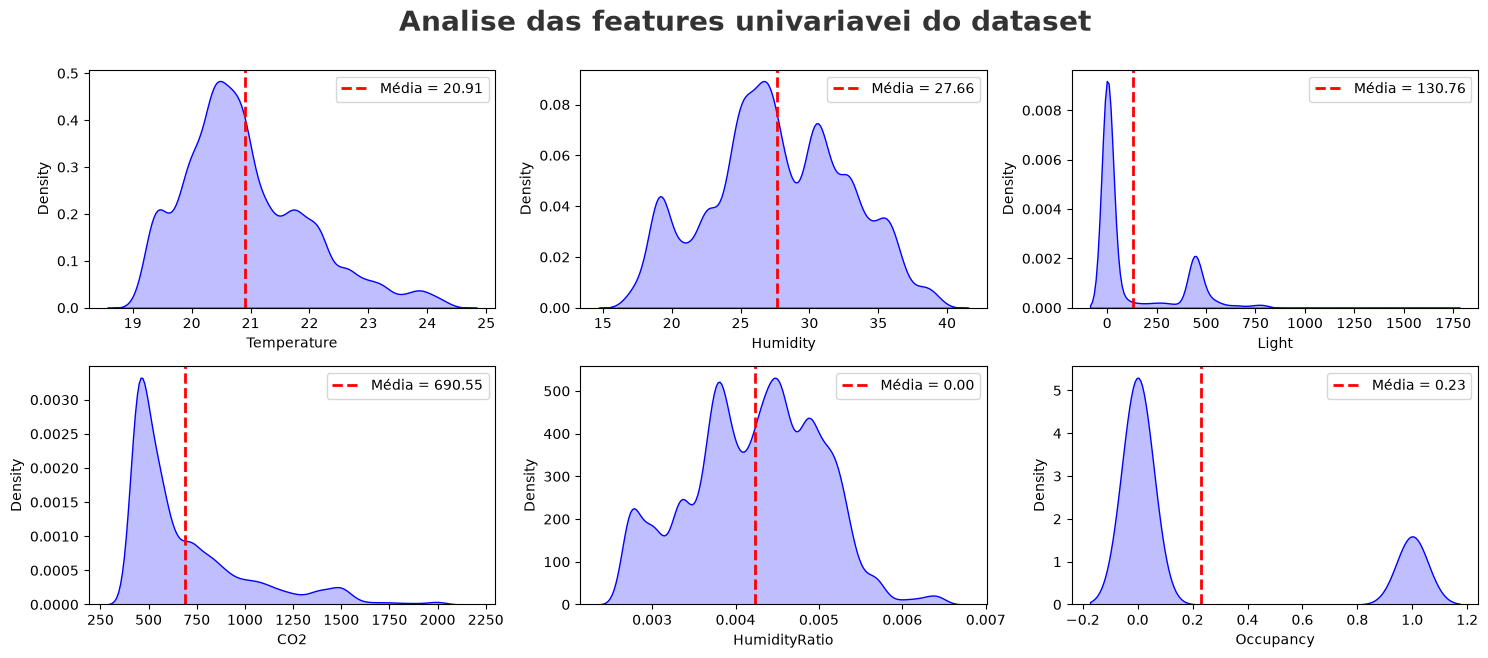

In [10]:
features_numericas = ["Temperature", "Humidity", "Light", "CO2", "HumidityRatio", "Occupancy"]

for data in datasets:
    plt.figure(figsize=(15,15))
    plt.suptitle("Analise das features univariavei do dataset", fontsize=20, fontweight='bold', alpha=0.8, y = 1.)
    
    for i in range(len(features_numericas)):
        plt.subplot(5,3, i + 1)
        
        media = data[features_numericas[i]].mean()
        plt.axvline(media, color="red", linestyle="--", linewidth=2, label=f"Média = {media:.2f}")
        
        sns.kdeplot(x = data[features_numericas[i]], fill=True, color = 'b')
        plt.xlabel(features_numericas[i])
        
        plt.legend()
        
    plt.tight_layout() 
    plt.show()

# Matriz Correlação Variáveis

In [11]:
def matriz_corr(df, nome=""):
    matriz        = df.corr()
    matriz_sem_date = df.drop(['date'], axis=1).corr()

    plt.figure(figsize=(10, 8))
    sns.heatmap(matriz, cmap='CMRmap', annot=True)
    plt.title(f"Matriz de correlação — {nome}",
              fontsize=14, fontweight="bold")
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(10, 8))
    sns.heatmap(matriz_sem_date, cmap='CMRmap', annot=True)
    plt.title(f"Matriz de correlação — {nome} (sem date)",
              fontsize=14, fontweight="bold")
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

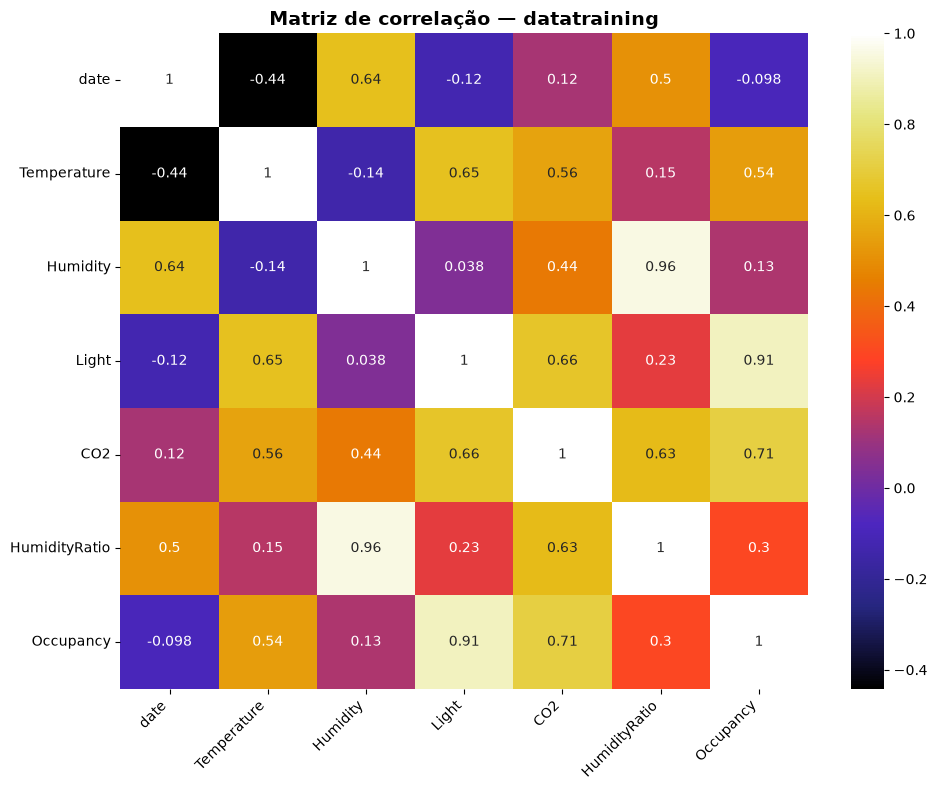

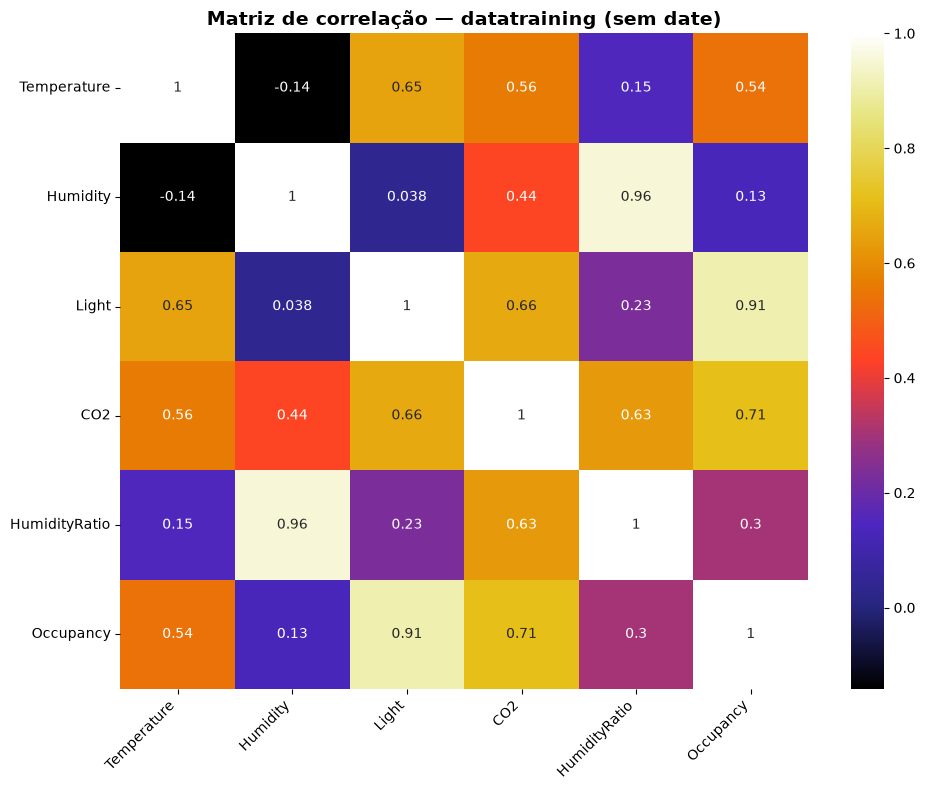

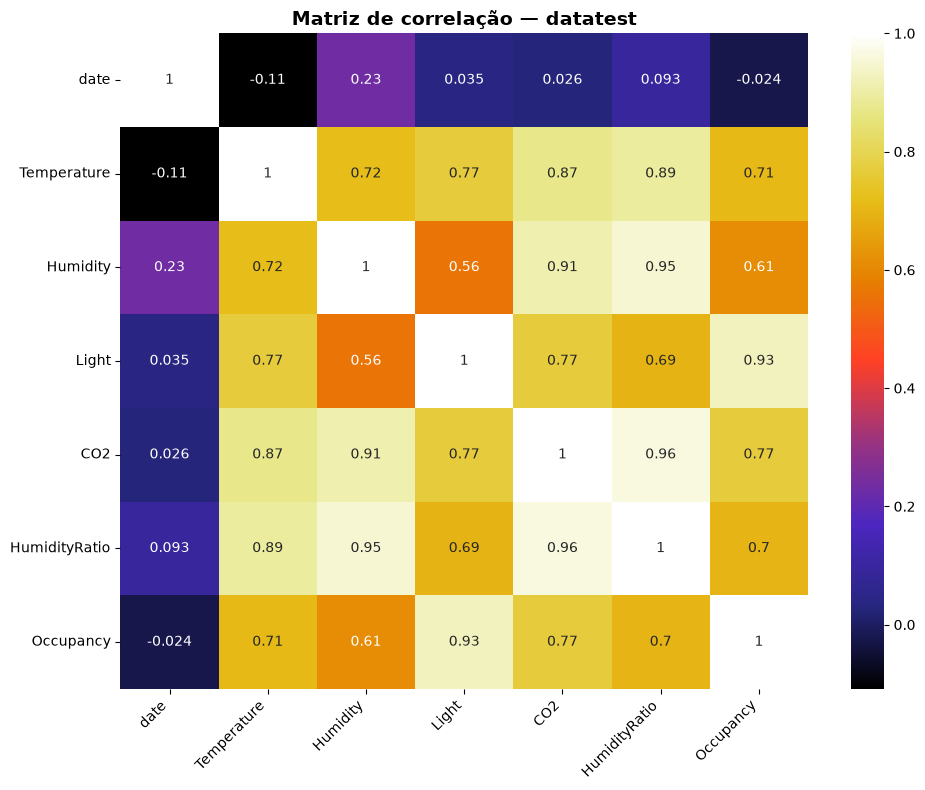

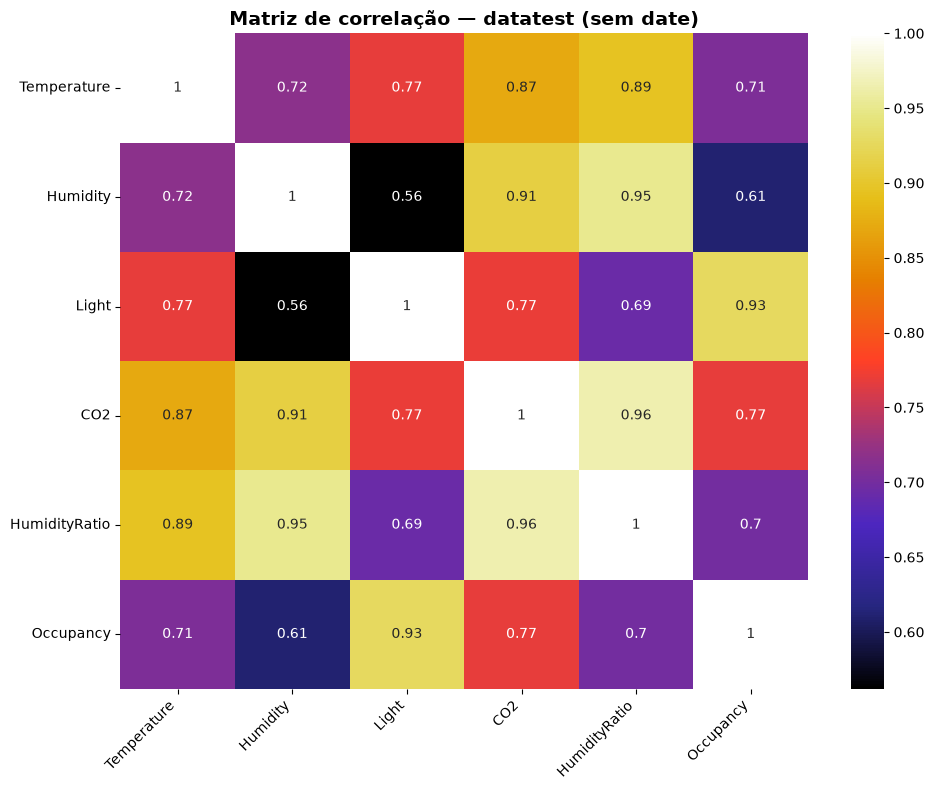

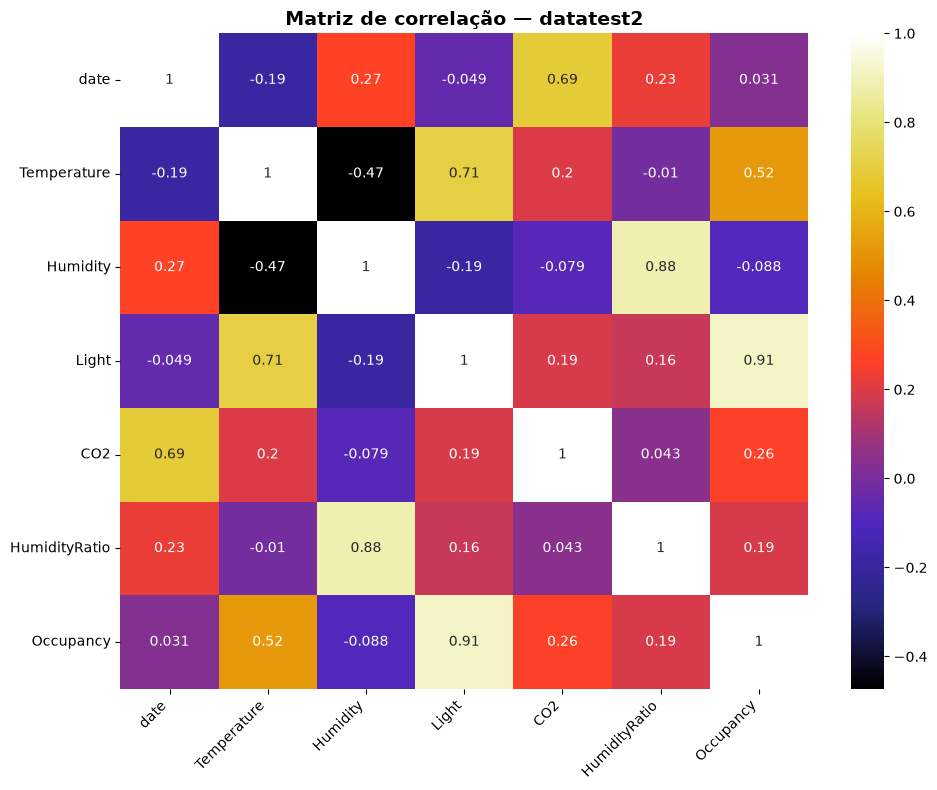

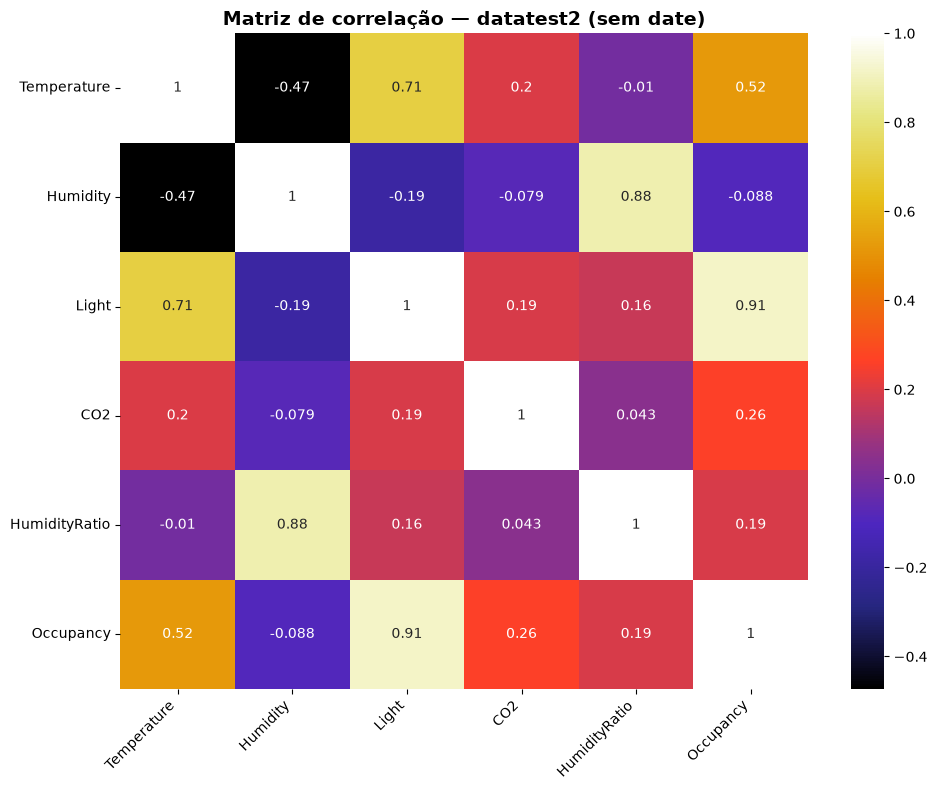

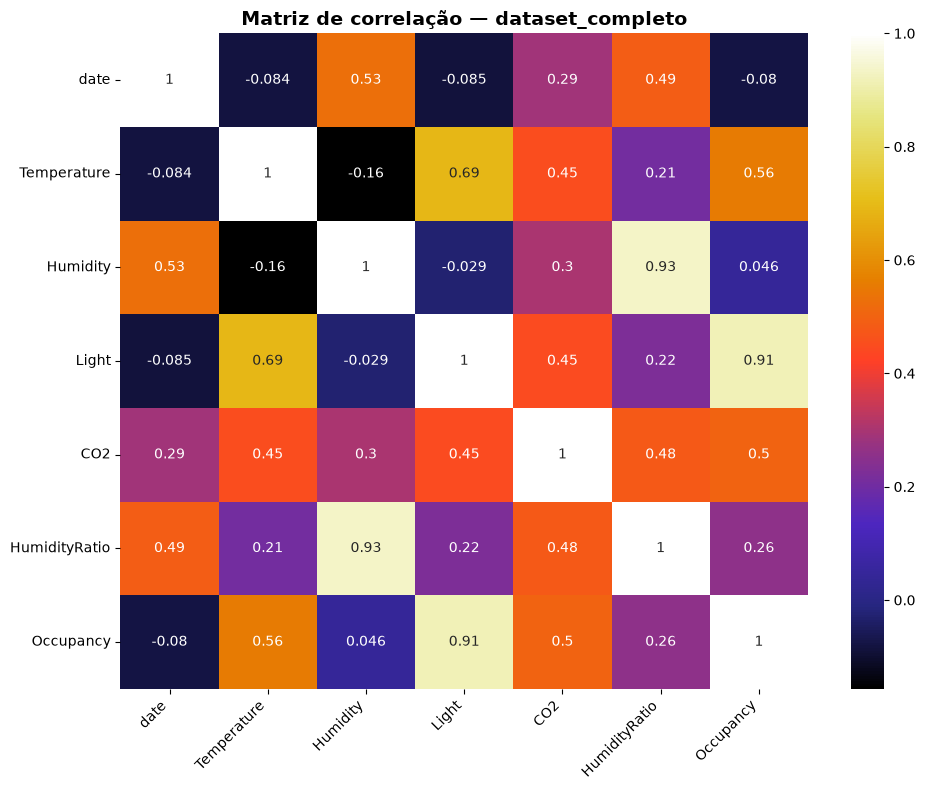

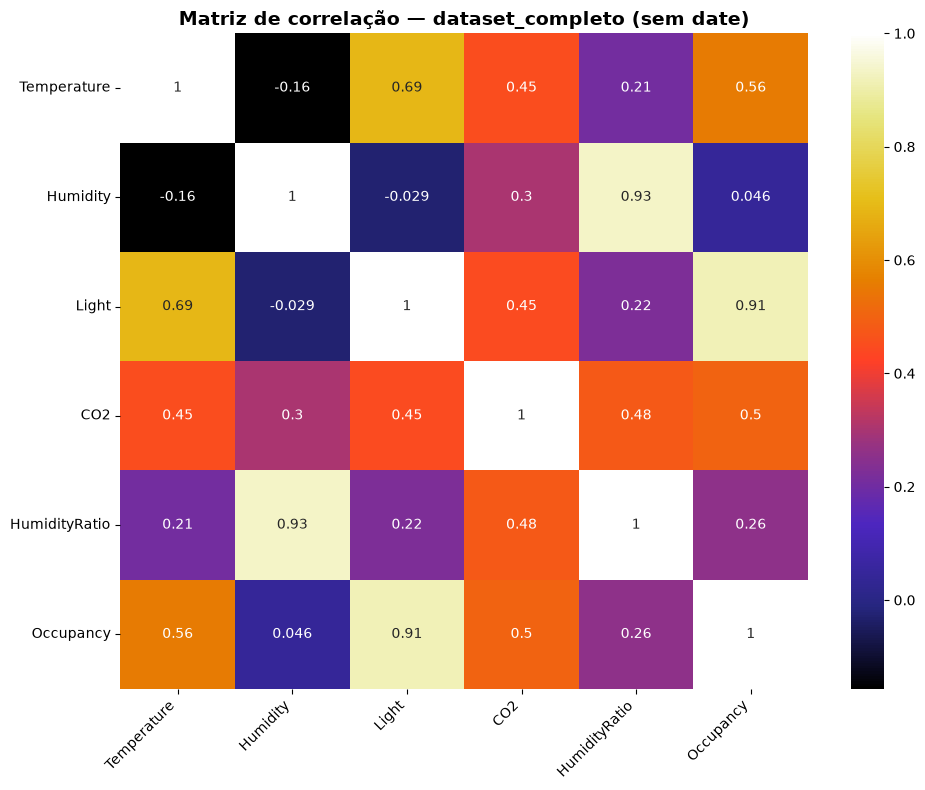

In [12]:
matriz_corr(datatraining, "datatraining")
matriz_corr(datatest, "datatest")
matriz_corr(datatest2, "datatest2")
matriz_corr(dataset_completo, "dataset_completo")

# Como é a distribuição de cada variavel com relação ao tempo

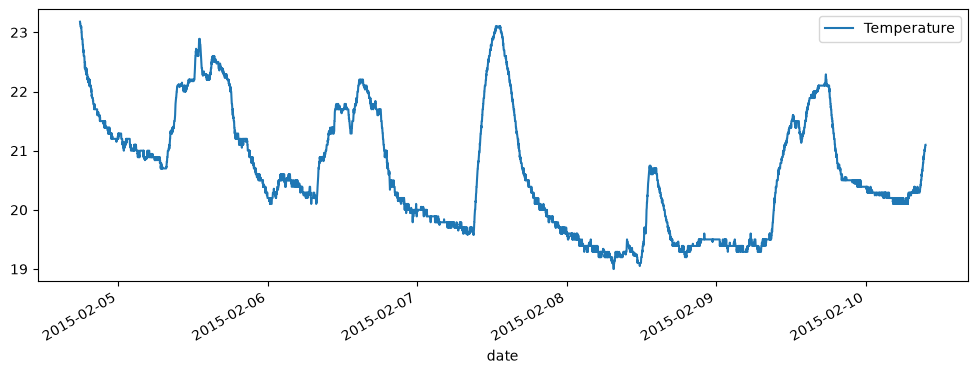

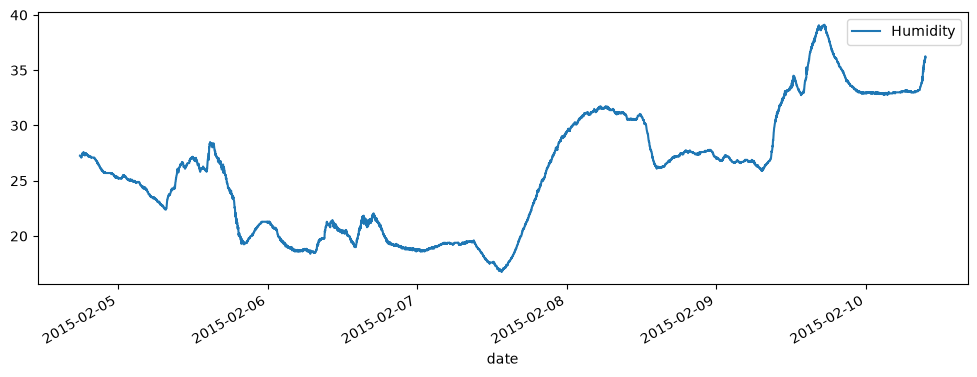

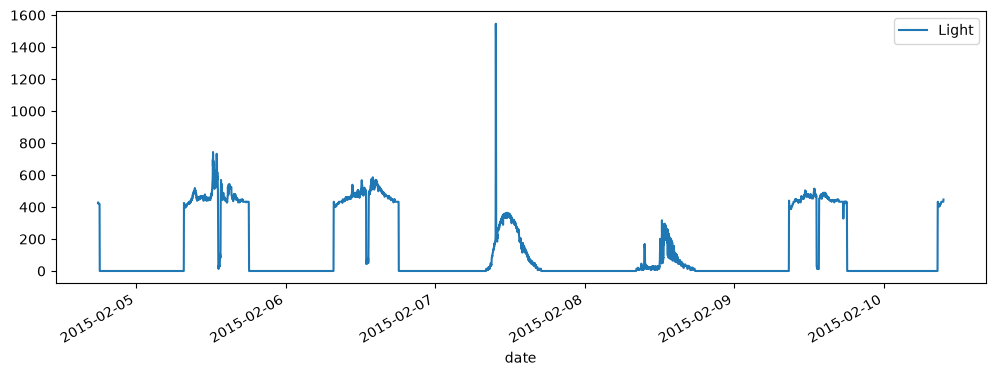

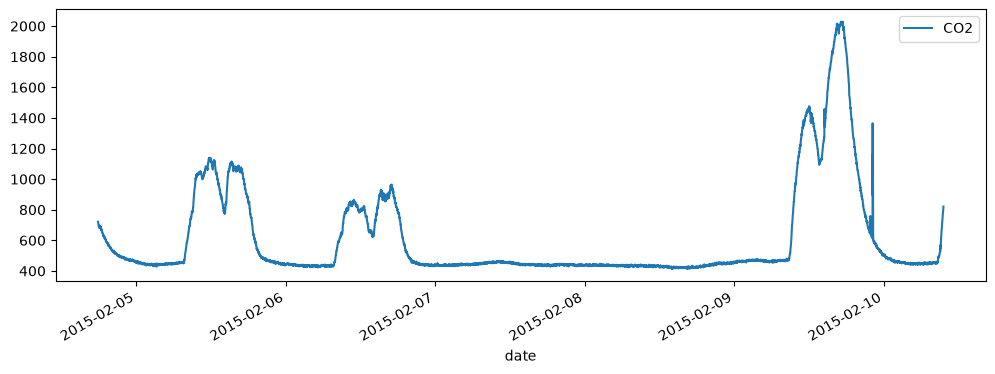

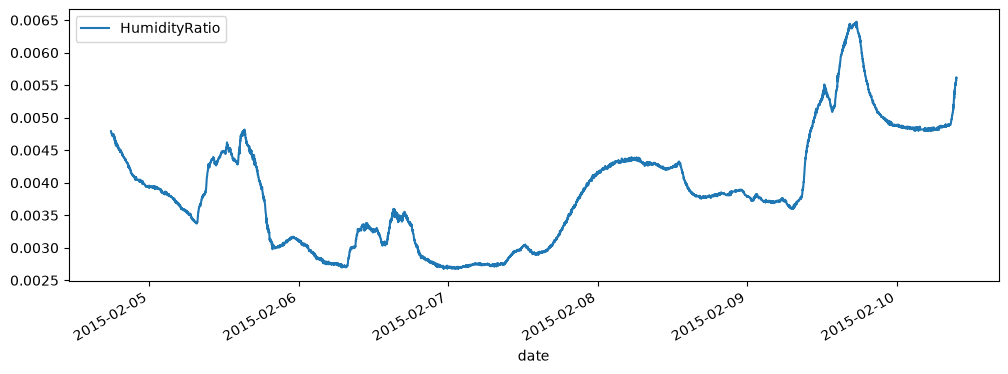

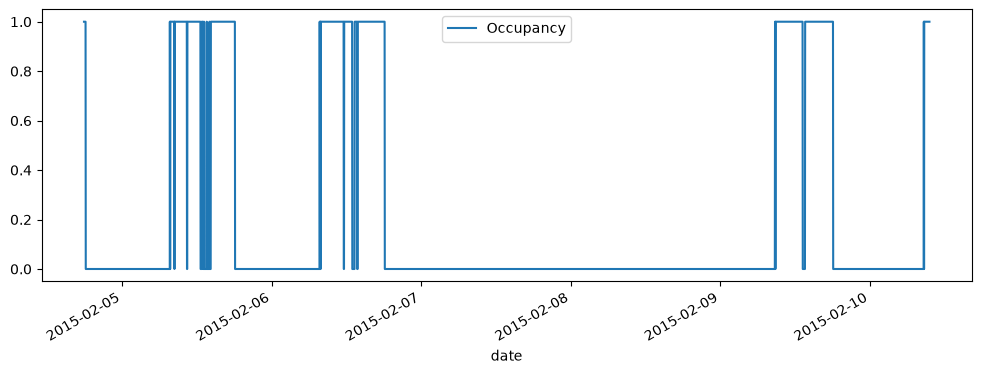

In [14]:
datatraining.sort_values('date')

for feature in features_numericas:
    datatraining.plot(x="date", y=feature, figsize=(12, 4))
    plt.show()